# Fashion-MNIST Classification Project
This notebook loads Fashion-MNIST, explores it, trains a baseline dense network and a CNN, evaluates both, and discusses results.

## 1. Setup

In [1]:
import numpy as np, matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix

np.random.seed(42); tf.random.set_seed(42)
class_names = ['T-shirt/top','Trouser','Pullover','Dress','Coat','Sandal','Shirt','Sneaker','Bag','Ankle boot']
print('TensorFlow', tf.__version__)

I0000 00:00:1791881068.169878     347 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791881068.610519     347 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1791881071.330792     347 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0


## 2. Load and explore the data

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()
print('Train:', x_train.shape, y_train.shape)
print('Test: ', x_test.shape, y_test.shape)
print('Pixel range:', x_train.min(), '-', x_train.max())
print('Class counts (train):', np.bincount(y_train))

Train: (60000, 28, 28) (60000,)
Test:  (10000, 28, 28) (10000,)
Pixel range: 0 - 255
Class counts (train): [6000 6000 6000 6000 6000 6000 6000 6000 6000 6000]


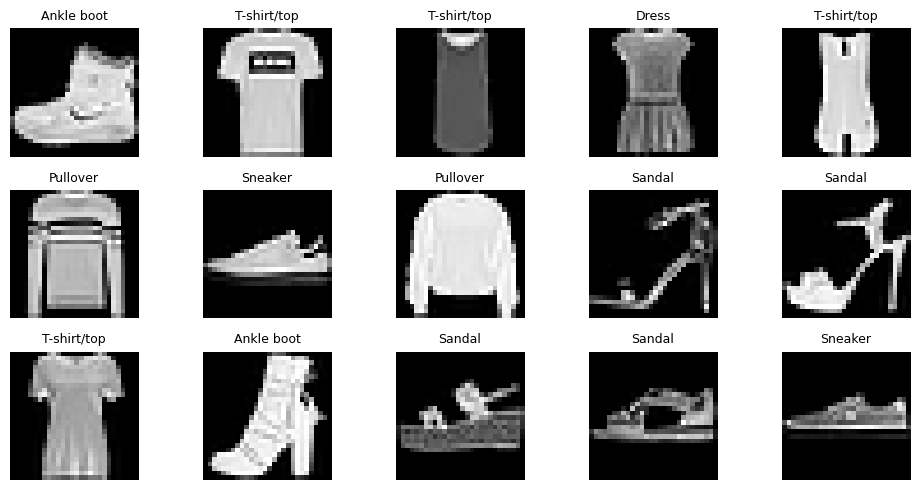

In [3]:
plt.figure(figsize=(10,5))
for i in range(15):
    plt.subplot(3,5,i+1)
    plt.imshow(x_train[i], cmap='gray'); plt.title(class_names[y_train[i]], fontsize=9); plt.axis('off')
plt.tight_layout(); plt.show()

## 3. Preprocessing
Scale pixels to [0, 1], add a channel dimension, and hold out 10% of the training data for validation.

In [4]:
x_train = (x_train / 255.0).astype('float32')[..., None]
x_test  = (x_test  / 255.0).astype('float32')[..., None]
n_val = 6000
x_val, y_val = x_train[:n_val], y_train[:n_val]
x_tr,  y_tr  = x_train[n_val:], y_train[n_val:]
print(x_tr.shape, x_val.shape, x_test.shape)

(54000, 28, 28, 1) (6000, 28, 28, 1) (10000, 28, 28, 1)


## 4. Baseline model: fully connected network

In [5]:
dense = keras.Sequential([
    layers.Input((28,28,1)), layers.Flatten(),
    layers.Dense(256, activation='relu'), layers.Dropout(0.3),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')])
dense.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
dense.summary()
h_dense = dense.fit(x_tr, y_tr, epochs=10, batch_size=128, validation_data=(x_val, y_val), verbose=2)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

...

422/422 - 5s - 12ms/step - accuracy: 0.8864 - loss: 0.3061 - val_accuracy: 0.8810 - val_loss: 0.3207


Epoch 9/10


422/422 - 5s - 13ms/step - accuracy: 0.8879 - loss: 0.2968 - val_accuracy: 0.8862 - val_loss: 0.3094


Epoch 10/10


422/422 - 5s - 13ms/step - accuracy: 0.8919 - loss: 0.2878 - val_accuracy: 0.8897 - val_loss: 0.3057


## 5. Convolutional neural network

In [6]:
cnn = keras.Sequential([
    layers.Input((28,28,1)),
    layers.Conv2D(32, 3, padding='same', activation='relu'), layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding='same', activation='relu'), layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Flatten(), layers.Dropout(0.4),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')])
cnn.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
cnn.summary()
es = keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=3, restore_best_weights=True)
h_cnn = cnn.fit(x_tr, y_tr, epochs=12, batch_size=128, validation_data=(x_val, y_val), callbacks=[es], verbose=2)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 422,026 (1.61 MB)

 Trainable params: 421,834 (1.61 MB)

 Non-trainable params: 192 (768.00 B)

...

422/422 - 81s - 192ms/step - accuracy: 0.9407 - loss: 0.1569 - val_accuracy: 0.9162 - val_loss: 0.2492


Epoch 9/12


422/422 - 83s - 196ms/step - accuracy: 0.9429 - loss: 0.1464 - val_accuracy: 0.9202 - val_loss: 0.2419


Epoch 10/12


422/422 - 81s - 193ms/step - accuracy: 0.9482 - loss: 0.1359 - val_accuracy: 0.9095 - val_loss: 0.2847


## 6. Training curves

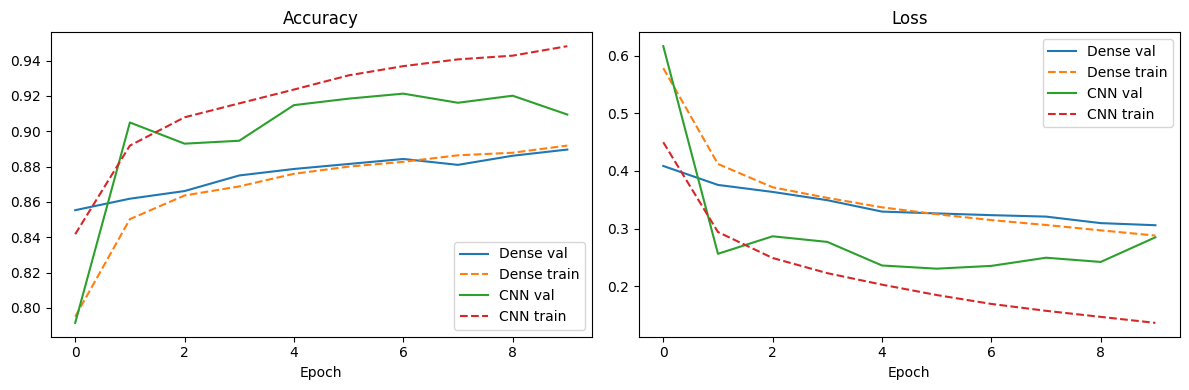

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12,4))
for name, h in [('Dense', h_dense), ('CNN', h_cnn)]:
    ax[0].plot(h.history['val_accuracy'], label=name+' val')
    ax[0].plot(h.history['accuracy'], '--', label=name+' train')
    ax[1].plot(h.history['val_loss'], label=name+' val')
    ax[1].plot(h.history['loss'], '--', label=name+' train')
ax[0].set_title('Accuracy'); ax[1].set_title('Loss')
for a in ax: a.set_xlabel('Epoch'); a.legend()
plt.tight_layout(); plt.show()

## 7. Evaluation on the test set

In [8]:
for name, m in [('Dense', dense), ('CNN', cnn)]:
    loss, acc = m.evaluate(x_test, y_test, verbose=0)
    print(f'{name}: test loss = {loss:.4f}, test accuracy = {acc:.4f}')

Dense: test loss = 0.3374, test accuracy = 0.8792


CNN: test loss = 0.2651, test accuracy = 0.9118


In [9]:
probs = cnn.predict(x_test, verbose=0)
y_pred = probs.argmax(axis=1)
print(classification_report(y_test, y_pred, target_names=class_names, digits=3))

              precision    recall  f1-score   support

 T-shirt/top      0.849     0.890     0.869      1000
     Trouser      0.990     0.983     0.986      1000
    Pullover      0.851     0.876     0.863      1000
       Dress      0.903     0.926     0.914      1000
        Coat      0.824     0.875     0.849      1000
      Sandal      0.989     0.978     0.983      1000
       Shirt      0.799     0.674     0.731      1000
     Sneaker      0.936     0.988     0.962      1000
         Bag      0.988     0.982     0.985      1000
  Ankle boot      0.985     0.946     0.965      1000

    accuracy                          0.912     10000
   macro avg      0.911     0.912     0.911     10000
weighted avg      0.911     0.912     0.911     10000



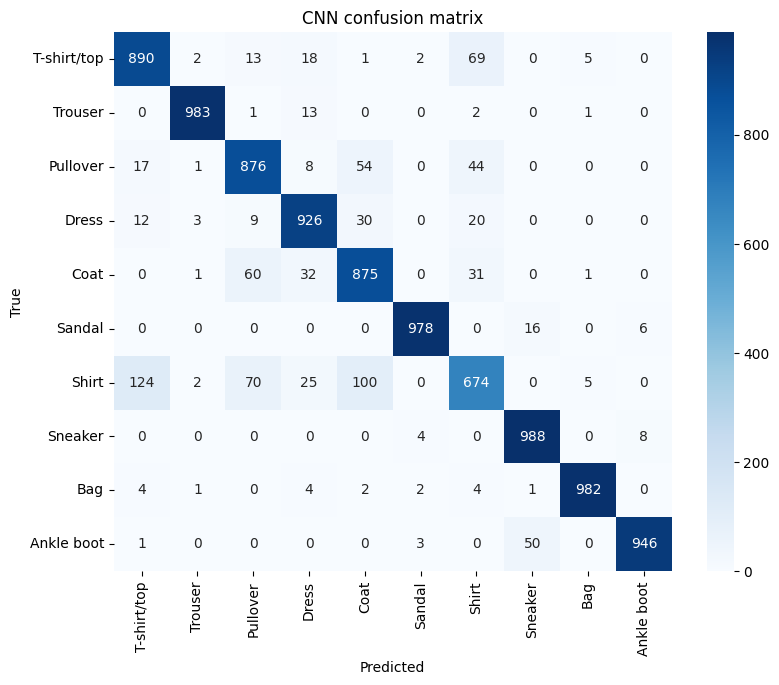

In [10]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(9,7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('CNN confusion matrix'); plt.show()

## 8. Error analysis

882 misclassified of 10000


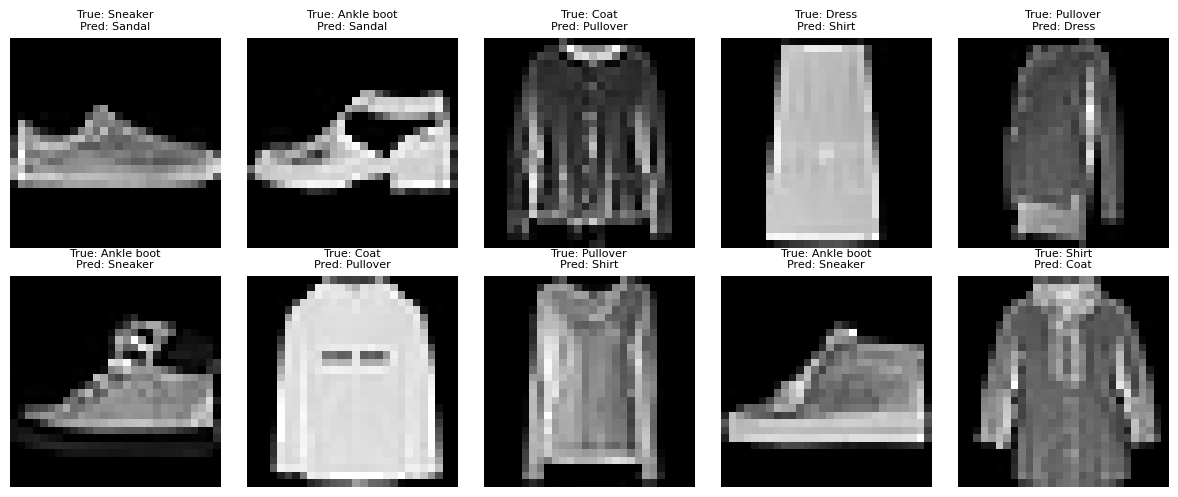

Shirt -> T-shirt/top: 124 errors
Shirt -> Coat: 100 errors
Shirt -> Pullover: 70 errors


In [11]:
wrong = np.where(y_pred != y_test)[0]
print(f'{len(wrong)} misclassified of {len(y_test)}')
plt.figure(figsize=(12,5))
for k, i in enumerate(wrong[:10]):
    plt.subplot(2,5,k+1)
    plt.imshow(x_test[i].squeeze(), cmap='gray')
    plt.title(f'True: {class_names[y_test[i]]}\nPred: {class_names[y_pred[i]]}', fontsize=8); plt.axis('off')
plt.tight_layout(); plt.show()

# Most confused pairs
cm_off = cm.copy(); np.fill_diagonal(cm_off, 0)
for idx in np.dstack(np.unravel_index(np.argsort(-cm_off.ravel())[:3], cm.shape))[0]:
    print(f'{class_names[idx[0]]} -> {class_names[idx[1]]}: {cm_off[idx[0], idx[1]]} errors')

## 9. Discussion
**Which model performed better, and why?** The CNN outperforms the dense baseline (see the test accuracies above). Convolutions exploit local spatial structure and share weights across the image, so they learn edge and texture features that a flattened dense network cannot capture as efficiently.

**Where does the model struggle?** Errors concentrate in visually similar upper-body garments, especially *Shirt* vs *T-shirt/top*, *Pullover*, and *Coat*. Footwear and bags are classified almost perfectly. The classification report and confusion matrix above show this.

**Overfitting?** The training curves show training accuracy above validation accuracy for both models; dropout, batch normalization, and early stopping limit the gap.

**Possible improvements:** data augmentation (small shifts, horizontal flips), a deeper network or residual blocks, learning-rate scheduling, and ensembling.